In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv("/content/loan_data.csv")

In [6]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  

In [8]:
df.isnull().sum()

,0
person_age,0
person_gender,0
person_education,0
person_income,0
person_emp_exp,0
person_home_ownership,0
loan_amnt,0
loan_intent,0
loan_int_rate,0
loan_percent_income,0


In [9]:
df.duplicated().sum()

np.int64(0)

### 1. Target Variable Distribution
Let's check the distribution of `loan_status` to see the proportion of loan approvals vs defaults.

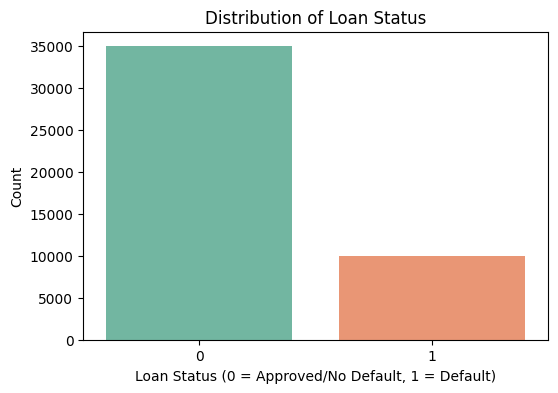

Class Proportions:
loan_status
0    77.777778
1    22.222222
Name: proportion, dtype: float64


In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x='loan_status', data=df, palette='Set2')
plt.title('Distribution of Loan Status')
plt.xlabel('Loan Status (0 = Approved/No Default, 1 = Default)')
plt.ylabel('Count')
plt.show()

print("Class Proportions:")
print(df['loan_status'].value_counts(normalize=True) * 100)

### 2. Numerical Features vs. Loan Status
Let's analyze how age, income, loan amount, and credit score correlate with the loan status.

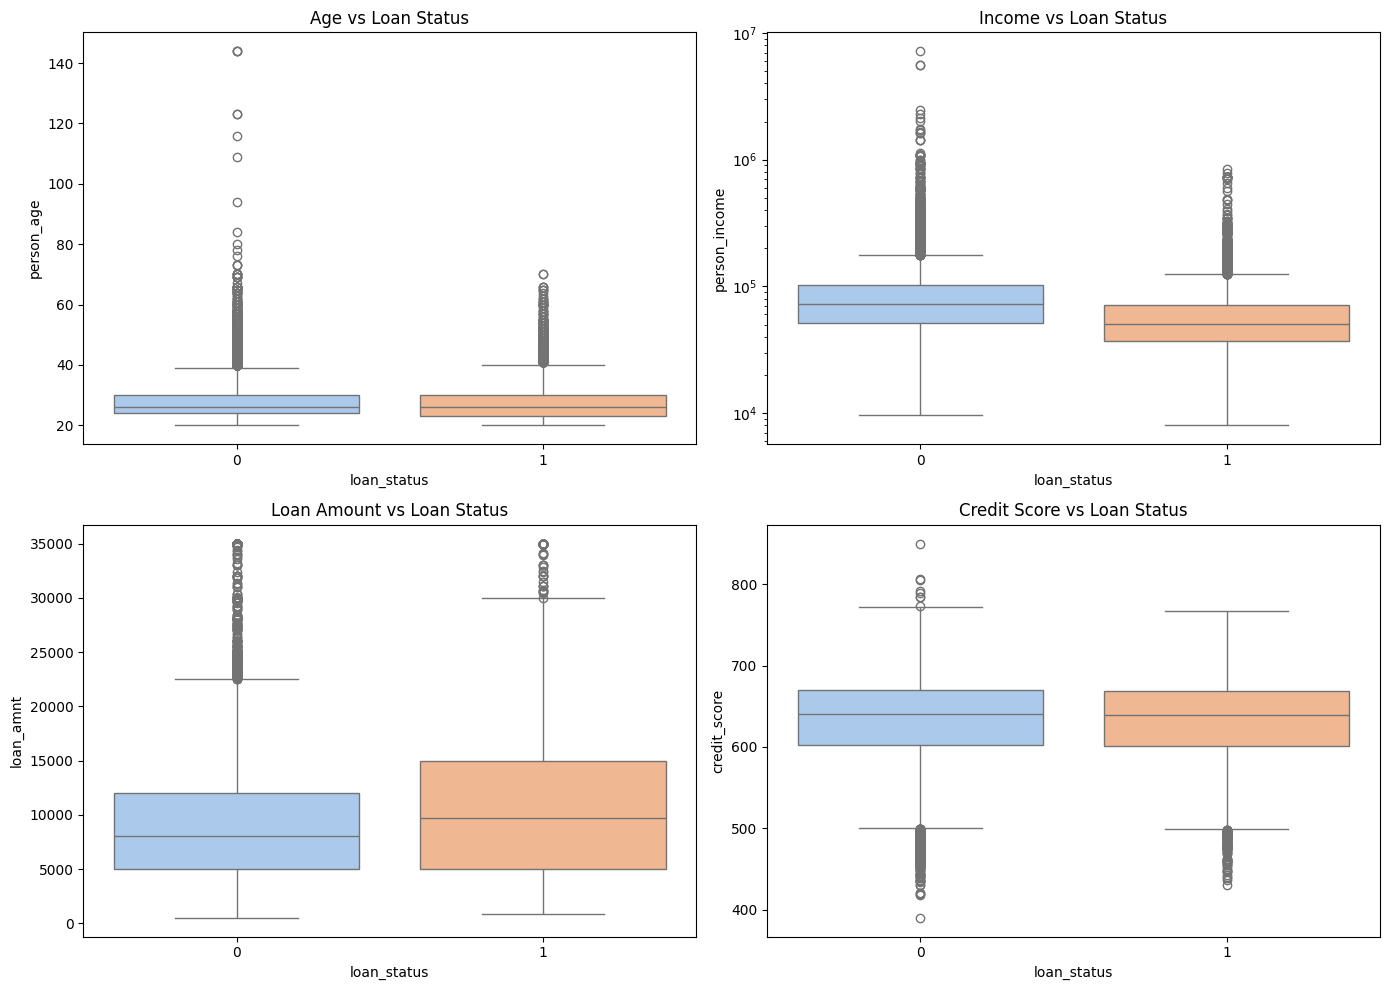

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(x='loan_status', y='person_age', data=df, ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('Age vs Loan Status')

sns.boxplot(x='loan_status', y='person_income', data=df, ax=axes[0, 1], palette='pastel')
axes[0, 1].set_title('Income vs Loan Status')
# Using log scale for income if there are large outliers
axes[0, 1].set_yscale('log')

sns.boxplot(x='loan_status', y='loan_amnt', data=df, ax=axes[1, 0], palette='pastel')
axes[1, 0].set_title('Loan Amount vs Loan Status')

sns.boxplot(x='loan_status', y='credit_score', data=df, ax=axes[1, 1], palette='pastel')
axes[1, 1].set_title('Credit Score vs Loan Status')

plt.tight_layout()
plt.show()

### 3. Categorical Features vs. Loan Status
Let's see how home ownership, education, and previous defaults relate to `loan_status`.

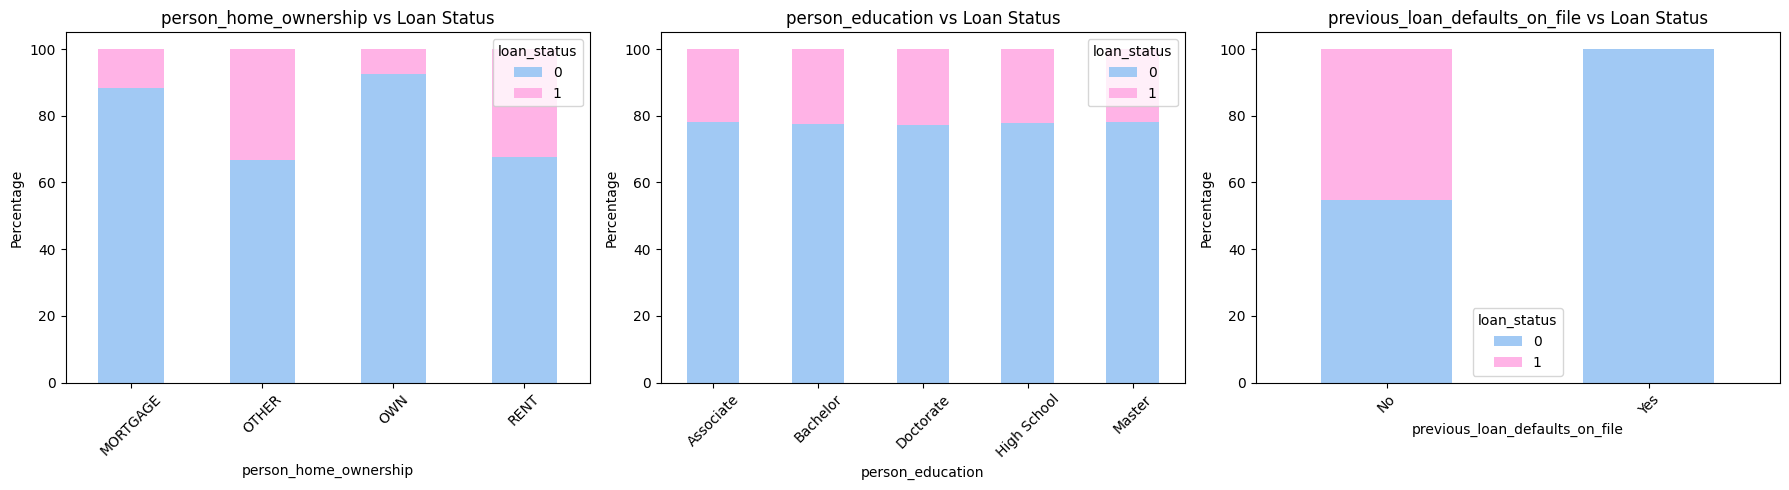

In [12]:
categorical_cols = ['person_home_ownership', 'person_education', 'previous_loan_defaults_on_file']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(categorical_cols):
    # Calculate percentage of status within each category
    grouped = df.groupby(col)['loan_status'].value_counts(normalize=True).unstack() * 100
    grouped.plot(kind='bar', stacked=True, ax=axes[i], color=['#a1c9f4', '#ffb3e6'])
    axes[i].set_title(f'{col} vs Loan Status')
    axes[i].set_ylabel('Percentage')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()

In [13]:
df

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


### 4. Encoding Categorical Variables for Naive Bayes
We will use Label Encoding for binary features (like Gender and Previous Defaults) and One-Hot Encoding for multi-class categorical features (like Home Ownership, Education, and Loan Intent) to keep the dataset compatible with multiple types of classifiers.

In [14]:
from sklearn.preprocessing import LabelEncoder

# Create a copy of the dataframe to keep the original raw data safe
df_encoded = df.copy()

# 1. Label Encoding for Binary Categorical Columns
binary_cols = ['person_gender', 'previous_loan_defaults_on_file']
le = LabelEncoder()
for col in binary_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])

# 2. One-Hot Encoding for remaining nominal/multi-class columns
nominal_cols = ['person_education', 'person_home_ownership', 'loan_intent']
df_encoded = pd.get_dummies(df_encoded, columns=nominal_cols, drop_first=True, dtype=int)

# Display the encoded dataset to verify columns
display(df_encoded.head())
print("Encoded dataset shape:", df_encoded.shape)

,person_age,person_gender,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,...,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,22.0,0,71948.0,0,35000.0,16.02,0.49,3.0,561,0,...,0,1,0,0,1,0,0,0,1,0
1,21.0,0,12282.0,0,1000.0,11.14,0.08,2.0,504,1,...,1,0,0,1,0,1,0,0,0,0
2,25.0,0,12438.0,3,5500.0,12.87,0.44,3.0,635,0,...,1,0,0,0,0,0,0,1,0,0
3,23.0,0,79753.0,0,35000.0,15.23,0.44,2.0,675,0,...,0,0,0,0,1,0,0,1,0,0
4,24.0,1,66135.0,1,35000.0,14.27,0.53,4.0,586,0,...,0,1,0,0,1,0,0,1,0,0


Encoded dataset shape: (45000, 23)


### 5. Train-Test Split and Model Training with Naive Bayes
We will now split our encoded data into training and testing sets, then train a Gaussian Naive Bayes model and evaluate its performance.

Accuracy Score: 0.8060

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7000
           1       0.66      0.27      0.38      2000

    accuracy                           0.81      9000
   macro avg       0.74      0.61      0.63      9000
weighted avg       0.78      0.81      0.77      9000



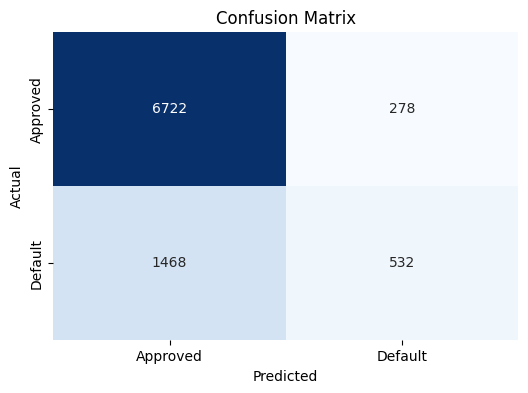

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Separate features and target
X = df_encoded.drop(columns=['loan_status'])
y = df_encoded['loan_status']

# Split into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train Gaussian Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Make predictions
y_pred = nb_model.predict(X_test)

# Evaluation
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Approved', 'Default'], yticklabels=['Approved', 'Default'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [18]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [25]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

GaussianNB()

In [26]:
y_pred = nb_model.predict(X_test)


In [29]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print = (accuracy_score(y_test, y_pred))
print = (classification_report(y_test, y_pred))
print = (confusion_matrix(y_test, y_pred))

In [30]:
print

array([[6722,  278],
       [1468,  532]])

In [31]:
accuracy

0.806

### 6. Removing Outliers & Retraining Gaussian Naive Bayes
We will use the IQR method to remove outliers from numerical columns and observe how it impacts our Naive Bayes model's performance.

In [34]:
# Restore the built-in print function if it was overwritten
import sys
if 'print' in globals() or 'print' in locals():
    try:
        del print
    except NameError:
        pass

import builtins
print_func = builtins.print

# Identify continuous numerical columns to filter outliers
num_cols = ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'credit_score']

# Keep a copy of the encoded dataframe
df_no_outliers = df_encoded.copy()

# Apply IQR method to filter outliers
for col in num_cols:
    Q1 = df_no_outliers[col].quantile(0.25)
    Q3 = df_no_outliers[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Filter the dataframe
    df_no_outliers = df_no_outliers[(df_no_outliers[col] >= lower_bound) & (df_no_outliers[col] <= upper_bound)]

print_func(f"Original dataset size: {df_encoded.shape[0]}")
print_func(f"Dataset size after removing outliers: {df_no_outliers.shape[0]}")

# Re-split features and target
X_clean = df_no_outliers.drop(columns=['loan_status'])
y_clean = df_no_outliers['loan_status']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean)

# Retrain model
nb_model_clean = GaussianNB()
nb_model_clean.fit(X_train_c, y_train_c)
y_pred_c = nb_model_clean.predict(X_test_c)

# Evaluation
accuracy_c = accuracy_score(y_test_c, y_pred_c)
print_func(f"\nNew Accuracy Score: {accuracy_c:.4f} (Before: {accuracy:.4f})")
print_func("\nNew Classification Report:")
print_func(classification_report(y_test_c, y_pred_c))

Original dataset size: 45000
Dataset size after removing outliers: 38052

New Accuracy Score: 0.8476 (Before: 0.8060)

New Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91      5936
           1       0.79      0.42      0.55      1675

    accuracy                           0.85      7611
   macro avg       0.82      0.69      0.73      7611
weighted avg       0.84      0.85      0.83      7611



In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  

### Removing Outliers
We will now filter our encoded dataset (`df_encoded`) using the Interquartile Range (IQR) method on our continuous columns to create a clean dataset `df_cleaned` free of extreme outliers.

In [36]:
# Continuous columns to filter
num_cols = ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'credit_score']

# Start with our encoded dataframe
df_cleaned = df_encoded.copy()

# Apply IQR filtering across all selected numerical columns
for col in num_cols:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Keep only rows within bounds
    df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & (df_cleaned[col] <= upper_bound)]

print(f"Original dataset row count: {df_encoded.shape[0]}")
print(f"Cleaned dataset row count: {df_cleaned.shape[0]}")
print(f"Removed {df_encoded.shape[0] - df_cleaned.shape[0]} rows containing outliers.")

# Preview the cleaned dataset
display(df_cleaned.head())

Original dataset row count: 45000
Cleaned dataset row count: 38052
Removed 6948 rows containing outliers.


,person_age,person_gender,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,...,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
1,21.0,0,12282.0,0,1000.0,11.14,0.08,2.0,504,1,...,1,0,0,1,0,1,0,0,0,0
2,25.0,0,12438.0,3,5500.0,12.87,0.44,3.0,635,0,...,1,0,0,0,0,0,0,1,0,0
5,21.0,0,12951.0,0,2500.0,7.14,0.19,2.0,532,0,...,1,0,0,1,0,0,0,0,0,1
9,21.0,0,12739.0,0,1600.0,14.74,0.13,3.0,640,0,...,1,0,0,1,0,0,0,0,0,1
11,21.0,0,13113.0,0,4500.0,8.63,0.34,2.0,651,0,...,0,0,0,1,0,0,1,0,0,0


In [37]:
df.shape

(45000, 14)

In [ ]:
new_model = GaussianNB()
new_model.fit(X_train_c, y_train_c)
y_pred_c = new_model

In [40]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [45]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop('loan_status', axis=1)
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [46]:
new_model = GaussianNB()
new_model.fit(X_train, y_train)
y_pred = new_model.predict(X_test)

In [47]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print = (accuracy_score(y_test, y_pred))
print = (classification_report(y_test, y_pred))
print = (confusion_matrix(y_test, y_pred))

In [48]:
accuracy

0.806